# Basin width and the shared basin

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/eleninisioti/continual_neuroevolution/blob/main/notebooks/basin_width.ipynb)

Why does ES forget less than the other methods? This notebook walks through the two measurements the paper uses to answer that question, and ends by redrawing the paper's basin figure (`fig:basin`) from the saved data.

1. **Basin width**: how far a solution's weights can be pushed in a random direction before the policy stops solving its task.
2. **Shared basin**: whether random moves around a solution, as large as the step the method actually takes over the next task, land on weights that solve *both* the current task and the next one.

In this notebook we measure them on pre-trained agents (ES and PPO) the ES and PPO centroids saved at the end of each task of one CartPole run with observation offsets. Everything runs in plain numpy (CartPole is re-implemented below), so the notebook needs neither JAX nor this repository's training code.

In [1]:
import json, os, pathlib, subprocess, sys

# On Colab (or anywhere without the repository) fetch it for the data files.
if not pathlib.Path('data/basin').exists():
    if not pathlib.Path('continual_neuroevolution').exists():
        subprocess.run(['git', 'clone', '--depth', '1',
                        'https://github.com/eleninisioti/continual_neuroevolution'], check=True)
    os.chdir('continual_neuroevolution/notebooks')

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, wilcoxon

DATA = pathlib.Path('data/basin')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

## 1. The task and the policy

A *task* is CartPole with a fixed offset vector added to every observation the policy sees. Task 0 has no offset; each later task draws one from $\mathcal N(0, I)$. CartPole fails when the pole passes 0.21 rad, so an offset of order 1 on the angle coordinate moves the policy's decision boundary to a different place in state space: the optimum moves.

The policy is the network every method searches on gymnax: 4 → 16 → 16 → 2 with ReLU, acting greedily. A saved agent is one flat vector of its 386 weights, tensor by tensor.

In [2]:
# CartPole-v1 as gymnax implements it, vectorised over policies and episodes.
G, M_CART, M_POLE, LENGTH, FORCE, TAU = 9.8, 1.0, 0.1, 0.5, 10.0, 0.02
M_TOT, PML = M_CART + M_POLE, M_POLE * LENGTH
THETA_MAX, X_MAX, MAX_STEPS = 12 * 2 * np.pi / 360, 2.4, 500

# The flat weight vector lists these tensors in order (flax's ravel_pytree: per layer, bias first).
SHAPES = [(16,), (4, 16), (16,), (16, 16), (2,), (16, 2)]
SIZES = [int(np.prod(s)) for s in SHAPES]


def unflatten(theta):
    out, i = [], 0
    for s, n in zip(SHAPES, SIZES):
        out.append(theta[..., i:i + n].reshape(theta.shape[:-1] + s))
        i += n
    return out


def act(thetas, obs):
    # Greedy actions of P policies (P, 386) on observations (P, E, 4).
    b0, W0, b1, W1, b2, W2 = unflatten(thetas)
    h = np.maximum(np.einsum('pei,pij->pej', obs, W0) + b0[:, None], 0)
    h = np.maximum(np.einsum('pei,pij->pej', h, W1) + b1[:, None], 0)
    return np.argmax(np.einsum('pei,pij->pej', h, W2) + b2[:, None], -1)


def returns(thetas, offset, episodes=10, seed=0):
    # Mean return of each policy over `episodes` episodes of the task with this offset.
    thetas = np.atleast_2d(thetas)
    rng = np.random.default_rng(seed)
    s = rng.uniform(-0.05, 0.05, size=(len(thetas), episodes, 4))
    ret, alive = np.zeros(s.shape[:2]), np.ones(s.shape[:2], bool)
    for _ in range(MAX_STEPS):
        a = act(thetas, s + offset)
        x, xd, th, thd = np.moveaxis(s, -1, 0)
        f = np.where(a == 1, FORCE, -FORCE)
        c, si = np.cos(th), np.sin(th)
        tmp = (f + PML * thd ** 2 * si) / M_TOT
        tha = (G * si - c * tmp) / (LENGTH * (4 / 3 - M_POLE * c ** 2 / M_TOT))
        xa = tmp - PML * tha * c / M_TOT
        s = np.stack([x + TAU * xd, xd + TAU * xa, th + TAU * thd, thd + TAU * tha], -1)
        ret += alive
        alive &= (np.abs(s[..., 0]) <= X_MAX) & (np.abs(s[..., 2]) <= THETA_MAX)
        if not alive.any():
            break
    return ret.mean(-1)

Two saved runs, one ES and one PPO (trial 2 of each), from the CartPole setting with ten offsets each visited twice (20 tasks). `centroid[t]` is the agent at the end of task `t` (for ES the mean of its search distribution; for PPO the policy itself) and `offsets[t]` that task's offset.

Returns are put on the paper's scale: 0 is the untrained network (a return of 10 on CartPole) and 1 the best return of any method (500). A policy **solves** a task when its rescaled return reaches 0.5.

In [3]:
runs = {m: dict(np.load(DATA / f'cartpole_{m}.npz')) for m in ('es', 'ppo')}
FLOOR, BEST = 10.0, 500.0
rescale = lambda r: (np.asarray(r) - FLOOR) / (BEST - FLOOR)

for m, run in runs.items():
    own = [rescale(returns(run['centroid'][t], run['offsets'][t]))[0] for t in range(len(run['centroid']))]
    print(f'{m:4s} rescaled return of each centroid on its own task:', np.round(own, 2))

es   rescaled return of each centroid on its own task: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
ppo  rescaled return of each centroid on its own task: [ 0.87  1.    1.    1.   -0.   -0.   -0.    1.    1.    0.97  1.    1.
  1.    1.   -0.    1.    1.    1.    1.    1.  ]


## 2. Perturbing the weights, at the right scale

To probe the basin we add random noise to the weights and check whether the policy still works. The size of that noise needs care: a ReLU layer can be multiplied by any $c>0$ and the next divided by $c$ without changing the policy, so a fixed noise size would call the same function sharp or flat depending on how its weights happen to be scaled (Dinh et al., 2017). Following Li et al. (2018), we scale the noise **per tensor**: for every weight matrix and bias $\theta_\ell$,

$$\tilde\theta_\ell = \theta_\ell + \epsilon\,\lVert\theta_\ell\rVert\,\frac{\xi_\ell}{\lVert\xi_\ell\rVert},\qquad \xi_\ell \sim \mathcal N(0, I).$$

A radius $\epsilon = 1$ moves every tensor by its own norm.

In [4]:
def tensor_norms(v):
    # Norm of every tensor of flat vector(s) v, repeated over that tensor's entries.
    parts = np.split(v, np.cumsum(SIZES)[:-1], axis=-1)
    return np.concatenate([np.repeat(np.linalg.norm(p, axis=-1, keepdims=True), n, -1)
                           for p, n in zip(parts, SIZES)], -1)


def directions(n, seed=0):
    # n random Gaussian directions, unit norm in every tensor.
    e = np.random.default_rng(seed).standard_normal((n, sum(SIZES)))
    return e / tensor_norms(e)


def perturb(theta, eps, dirs):
    return theta + eps * tensor_norms(theta) * dirs

A quick check of why this matters. Rescale the first layer of a PPO agent by 10 and the second by 1/10: the policy is the same function. Noise of a fixed size disagrees about the two copies; relative noise does not.

In [5]:
t = 18                                             # a checkpoint that solves its task
theta, off = runs['ppo']['centroid'][t].copy(), runs['ppo']['offsets'][t]
i0, i1, i2 = np.cumsum(SIZES)[[1, 2, 3]]          # end of layer 0, start and end of layer 1's kernel
rescaled = theta.copy()
rescaled[:i0] *= 10                                # layer 0 (bias and kernel) x 10
rescaled[i1:i2] /= 10                              # layer 1's kernel / 10 (its bias stays)

dirs = directions(64, seed=1)
print('unperturbed:          ', rescale(returns(np.stack([theta, rescaled]), off)).round(2))
noise = np.random.default_rng(1).standard_normal((64, sum(SIZES)))
absolute = lambda t: t + 0.03 * noise                              # the same absolute noise for both
print('absolute noise (0.03):', np.round([rescale(returns(absolute(t), off)).mean() for t in (theta, rescaled)], 2))
print('relative noise (0.03):', np.round([rescale(returns(perturb(t, 0.03, dirs), off)).mean() for t in (theta, rescaled)], 2))

unperturbed:           [1. 1.]
absolute noise (0.03): [0.71 0.22]
relative noise (0.03): [0.46 0.46]


## 3. Basin width

The basin of a solution is the region of weight space around it where the policy still solves its task. We take a checkpoint, draw 64 random directions, and follow each of them at the radii $\epsilon \in \{0.001, 0.003, \dots, 1, 3\}$. Two thresholds turn these perturbations into one number:

1. **Per perturbed policy:** it has *lost the task* when its rescaled return falls below 0.5 (`SOLVED`). At each radius we record the share of the 64 directions that lost the task, which gives a curve of share against radius.
2. **On that curve:** the **width** is the radius at which the share reaches one half (`crossing(..., level=0.5)`), interpolated log-linearly between radii.

Each perturbed policy gets fresh episodes. As a control for evaluation noise, the paper also scores a few unperturbed copies of the checkpoint (radius 0 below).

In [6]:
LADDER = np.array([0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0])
N_DIR, SOLVED = 64, 0.5


def loss_curve(theta, offset, seed=0):
    # Share of N_DIR random directions that no longer solve the task, at each radius.
    dirs = directions(N_DIR, seed)
    points = np.concatenate([perturb(theta, eps, dirs) for eps in LADDER])
    scores = rescale(returns(points, offset, seed=seed + 1)).reshape(len(LADDER), N_DIR)
    return (scores < SOLVED).mean(1)


def crossing(curve, radii=LADDER, level=0.5):
    # Radius where the loss curve reaches `level`, log-linear between the ladder's radii.
    curve = np.asarray(curve)
    if curve[0] >= level:
        return radii[0]
    if curve[-1] < level:
        return radii[-1]
    i = int(np.argmax(curve >= level))
    f = (level - curve[i - 1]) / (curve[i] - curve[i - 1])
    return 10 ** (np.log10(radii[i - 1]) + f * np.log10(radii[i] / radii[i - 1]))

The paper measures the checkpoints of the second half of each run, and pools the last five of them that solve their own task. A checkpoint's own task is the one it was just trained on.

es   checkpoints [14, 15, 16, 17, 18]  width = 0.445 x tensor norm
ppo  checkpoints [15, 16, 17, 18]  width = 0.031 x tensor norm


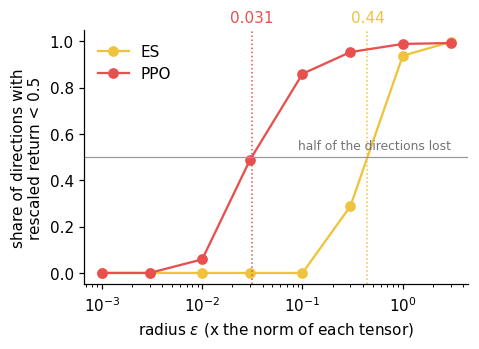

ES basin is 14.3x wider than PPO's on this pair of runs


In [7]:
def solved_window(run, k=5):
    # Last k checkpoints (that have a next task) that solve their own task.
    T = len(run['centroid'])
    ok = [t for t in range(T - 1 - k, T - 1)
          if rescale(returns(run['centroid'][t], run['offsets'][t]))[0] >= SOLVED]
    return ok


curves, widths = {}, {}
for m, run in runs.items():
    ts = solved_window(run)
    curves[m] = np.mean([loss_curve(run['centroid'][t], run['offsets'][t], seed=t) for t in ts], 0)
    widths[m] = crossing(curves[m])
    print(f'{m:4s} checkpoints {ts}  width = {widths[m]:.3f} x tensor norm')

colours = {'es': '#F0C33C', 'ppo': '#E8504F'}
fig, ax = plt.subplots(figsize=(4.5, 3))
for m, c in curves.items():
    ax.plot(LADDER, c, 'o-', color=colours[m], label=m.upper())
    # The width: where the curve crosses the half-lost line.
    ax.axvline(widths[m], color=colours[m], ls=':', lw=1)
    ax.text(widths[m], 1.02, f'{widths[m]:.2g}', color=colours[m], ha='center', va='bottom',
            transform=ax.get_xaxis_transform())
ax.axhline(0.5, color='0.6', lw=0.8)
ax.text(LADDER[-1], 0.52, 'half of the directions lost', color='0.45', fontsize=8, ha='right', va='bottom')
ax.set_xscale('log'); ax.set_xlabel(r'radius $\epsilon$ (x the norm of each tensor)')
ax.set_ylabel('share of directions with\nrescaled return < 0.5'); ax.legend(frameon=False, loc='upper left')
plt.show()
print(f'ES basin is {widths["es"] / widths["ppo"]:.1f}x wider than PPO\'s on this pair of runs')

### Seeing the basin

The width compresses a basin into a single radius. To see the basin itself we draw a two-dimensional slice of weight space, as in Figure 1 of the paper (`fig:overview`). The slice passes through the checkpoint $\theta_A$ at the end of task A:

* the **horizontal axis** runs along the method's own move over the next task, from $\theta_A$ (circle, $x=0$) to $\theta_B$ (diamond, $x=1$);
* the **vertical axis** is a random direction orthogonal to that move, in units of $0.1\,\lVert\theta_A\rVert$, so its extent is comparable across methods.

At every point we score the policy on both tasks. Blue is where it solves A, orange where it solves B, and dark grey where it solves both. That dark overlap is what section 4 measures as the shared basin. We draw every checkpoint whose width went into the curves above, one column per switch. A panel is left empty when the method's checkpoint does not solve its own task. Each slice scores a 41 × 41 grid of policies, and all of them together take about a minute and a half.

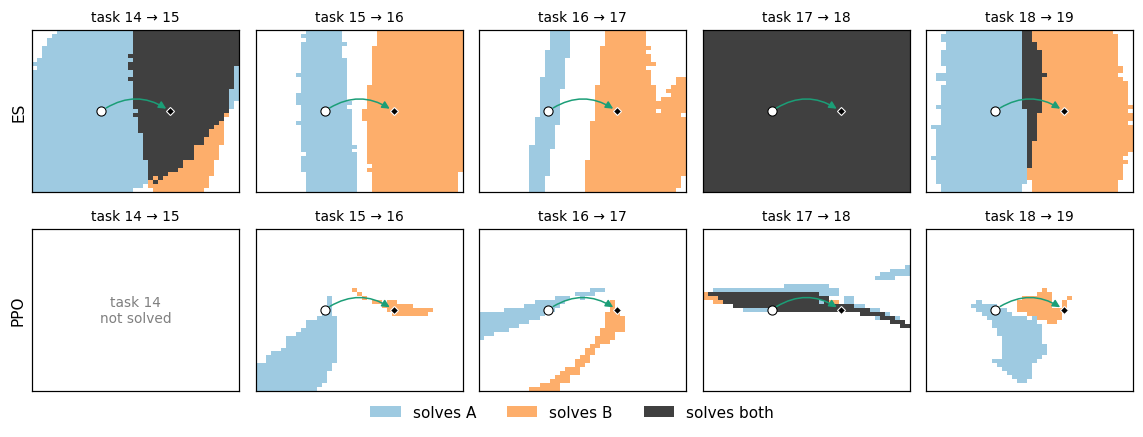

In [8]:
from matplotlib.colors import to_rgb
from matplotlib.patches import Patch

REGIONS = {(False, False): '#ffffff', (True, False): '#9ecae1',   # neither, A only
           (False, True): '#fdae6b', (True, True): '#404040'}     # B only, both


def landscape(theta_a, theta_b, off_a, off_b, n=41, xs=(-1, 2), ys=(-2.5, 2.5), seed=0):
    # Which points of the plane through theta_a, along theta_b - theta_a and a random orthogonal
    # direction of length 0.1 |theta_a|, solve task A and task B.
    e1 = theta_b - theta_a
    e2 = np.random.default_rng(seed).standard_normal(e1.shape)
    e2 -= e2 @ e1 / (e1 @ e1) * e1
    e2 *= 0.1 * np.linalg.norm(theta_a) / np.linalg.norm(e2)
    x, y = np.linspace(*xs, n), np.linspace(*ys, n)
    X, Y = np.meshgrid(x, y)
    points = theta_a + X.reshape(-1, 1) * e1 + Y.reshape(-1, 1) * e2
    on_a = rescale(returns(points, off_a, seed=seed + 1)).reshape(X.shape) >= SOLVED
    on_b = rescale(returns(points, off_b, seed=seed + 2)).reshape(X.shape) >= SOLVED
    return x, y, on_a, on_b


windows = {m: solved_window(run) for m, run in runs.items()}
switches = sorted(set().union(*windows.values()))          # one column per switch, aligned across methods
fig, axs = plt.subplots(len(runs), len(switches), figsize=(2.1 * len(switches), 2.0 * len(runs)), squeeze=False)
for r, (m, run) in enumerate(runs.items()):
    c, off = run['centroid'], run['offsets']
    for j, t in enumerate(switches):
        ax = axs[r, j]
        ax.set_xticks([]); ax.set_yticks([])
        ax.spines[['top', 'right']].set_visible(True)
        ax.set_title(f'task {t} → {t + 1}', fontsize=9)
        if t not in windows[m]:
            # The checkpoint does not solve its own task, so it has no basin to draw.
            ax.text(0.5, 0.5, f'task {t}\nnot solved', ha='center', va='center', color='0.5',
                    fontsize=9, transform=ax.transAxes)
            continue
        x, y, on_a, on_b = landscape(c[t], c[t + 1], off[t], off[t + 1], seed=t)
        img = np.zeros(on_a.shape + (3,))
        for (a, b), colour in REGIONS.items():
            img[(on_a == a) & (on_b == b)] = to_rgb(colour)
        ax.imshow(img, origin='lower', extent=[x[0], x[-1], y[0], y[-1]], aspect='auto', interpolation='nearest')
        ax.annotate('', xy=(1, 0), xytext=(0, 0), arrowprops=dict(arrowstyle='-|>', color='#1b9e77', lw=1,
                    shrinkA=4, shrinkB=3, connectionstyle='arc3,rad=-0.35'))
        ax.plot(0, 0, 'o', ms=6, mfc='white', mec='k', mew=0.7)
        ax.plot(1, 0, 'D', ms=4, mfc='k', mec='white', mew=0.7)
    axs[r, 0].set_ylabel(m.upper())
fig.legend(handles=[Patch(fc=REGIONS[True, False], label='solves A'), Patch(fc=REGIONS[False, True], label='solves B'),
                    Patch(fc=REGIONS[True, True], label='solves both')],
           loc='lower center', ncol=3, frameon=False, bbox_to_anchor=(0.5, 0))
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

**Reading the slices.** The ES basins fill most of the window, and at two of the five switches (14 → 15 and 17 → 18) the move ends in the dark overlap, so ES keeps task A. The PPO basins are thin bands, a few grid points wide on the vertical axis. Its move leaves the blue region at three of four switches, and even when it stays (17 → 18) the overlap is only a narrow strip along the path. The slices show one random direction each, so they illustrate the width measured above rather than replace it.

## 4. The shared basin

A wide basin only helps against forgetting if it also contains solutions of the **next** task. Around the checkpoint $\theta_A$ at the end of task A we take random moves and score every moved policy on **both** A and the next task B. The **shared basin** is the share of moves after which the policy solves both (rescaled return $\geq 0.5$ on each), averaged over the checkpoints of the second half of the run that solve their own task.

The size of the move matters. The paper's definition uses the same size for every method, radius 0.1 of each tensor's norm (one rung of the width ladder), so that a method is not rewarded simply for moving less. As a comparison we also use moves as large, in every tensor, as the step the method itself took over the next task, $\Delta = \theta_B - \theta_A$.

Scoring the actual step $\theta_B$ on task A separates two reasons to forget A:
* random moves of the method's own size already lose A, so the basin is too narrow for the distance the method travels;
* random moves keep A but the method's own move does not, so the problem is the *direction* of the move.

In [9]:
def shared_basin(theta_a, theta_b, off_a, off_b, n=N_DIR, seed=0):
    dirs = directions(n, seed)
    moves = {'radius 0.1': theta_a + 0.1 * tensor_norms(theta_a) * dirs,
             'own step': theta_a + tensor_norms(theta_b - theta_a) * dirs}
    out = {}
    for name, moved in moves.items():
        on_a = rescale(returns(moved, off_a, seed=seed + 1))
        on_b = rescale(returns(moved, off_b, seed=seed + 2))
        out[name] = np.mean((on_a >= SOLVED) & (on_b >= SOLVED))
        if name == 'own step':
            out['A kept, random own-size moves'] = np.mean(on_a >= SOLVED)
    out['A kept, actual step'] = float(rescale(returns(theta_b, off_a, seed=seed + 3))[0] >= SOLVED)
    return out


for m, run in runs.items():
    c, off = run['centroid'], run['offsets']
    T = len(c)
    rows = [shared_basin(c[t], c[t + 1], off[t], off[t + 1], seed=t) for t in range(T // 2, T - 1)
            if rescale(returns(c[t], off[t]))[0] >= SOLVED]
    print(f'{m.upper():4s} ({len(rows)} checkpoints)  ' +
          ',  '.join(f'{k}: {np.mean([r[k] for r in rows]):.2f}' for k in rows[0]))

ES   (9 checkpoints)  radius 0.1: 0.15,  own step: 0.16,  A kept, random own-size moves: 0.87,  A kept, actual step: 0.33
PPO  (8 checkpoints)  radius 0.1: 0.02,  own step: 0.01,  A kept, random own-size moves: 0.20,  A kept, actual step: 0.25


## 5. From one run to the paper's figure

The paper repeats these measurements on every trial (10 per method), every method (GA, ES, PPO, TRAC-PPO, ReDo-PPO, C-CHAIN, PBT-PPO) and every classic control and MiniGrid setting. The steps are the ones above:

* **Width relative to PPO.** In each setting, the ratio of a method's geometric mean width over trials to PPO's. A Mann-Whitney U test over trials (Holm-corrected over settings) gives the stars on a point. The bar is the median over settings, tested with a Wilcoxon signed-rank test of log ratio = 0.
* **Shared basin vs. the trade-off.** One point per setting and method: the shared basin against LA − F of Figure 2 (both rescaled per setting as in the paper). Methods that only ever learn one of two alternating tasks (*frozen*) are left out: they forget nothing because they never learn the other task.

`data/basin/basin_width.json` holds the per-trial widths and `data/basin/shared_basin.json` the per-setting shared basins, both as computed for the paper.

In [10]:
NAMES = {'ga': 'GA', 'es': 'ES', 'ppo': 'PPO', 'trac': 'TRAC-PPO', 'redo': 'ReDo-PPO',
         'cchain': 'C-CHAIN', 'pbt': 'PBT-PPO'}
COLOURS = {'ga': '#4CBB47', 'es': '#F0C33C', 'ppo': '#E8504F', 'trac': '#F08C4B',
           'redo': '#8B4A2B', 'cchain': '#7B5EA7', 'pbt': '#B5306B'}
MARKERS = {'Noise': 'o', 'Physics': 's', 'Action reversal': '^', 'Sequences': 'D'}
NE = {'ga', 'es'}
stars = lambda p: '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else ''

widths_data = json.loads((DATA / 'basin_width.json').read_text())['settings']
shared = json.loads((DATA / 'shared_basin.json').read_text())['points']


def holm(ps):
    order, adj, running = np.argsort(ps), np.empty(len(ps)), 0.0
    for rank, i in enumerate(order):
        running = max(running, min(1.0, (len(ps) - rank) * ps[i]))
        adj[i] = running
    return adj


from scipy.stats import mannwhitneyu
ratios = {}   # method -> [(setting, log2 ratio to PPO, Holm p)]
for m in ['ga', 'es', 'trac', 'redo', 'cchain', 'pbt']:
    rows = [(s, np.log2(d['widths'][m]).mean() - np.log2(d['widths']['ppo']).mean(),
             mannwhitneyu(np.log(d['widths'][m]), np.log(d['widths']['ppo'])).pvalue)
            for s, d in widths_data.items() if d['widths'].get(m) and d['widths'].get('ppo')]
    adj = holm(np.array([r[2] for r in rows]))
    ratios[m] = [(s, lr, p) for (s, lr, _), p in zip(rows, adj)]

for m, rows in ratios.items():
    v = np.array([r[1] for r in rows])
    print(f'{NAMES[m]:9s} median width / PPO = {2 ** np.median(v):.2f}  (Wilcoxon p = {wilcoxon(v).pvalue:.2g}, {len(v)} settings)')

GA        median width / PPO = 2.30  (Wilcoxon p = 0.13, 13 settings)
ES        median width / PPO = 3.89  (Wilcoxon p = 0.00024, 13 settings)
TRAC-PPO  median width / PPO = 1.54  (Wilcoxon p = 0.00024, 13 settings)
ReDo-PPO  median width / PPO = 1.15  (Wilcoxon p = 0.59, 13 settings)
C-CHAIN   median width / PPO = 1.36  (Wilcoxon p = 0.00024, 13 settings)
PBT-PPO   median width / PPO = 1.92  (Wilcoxon p = 0.00024, 13 settings)


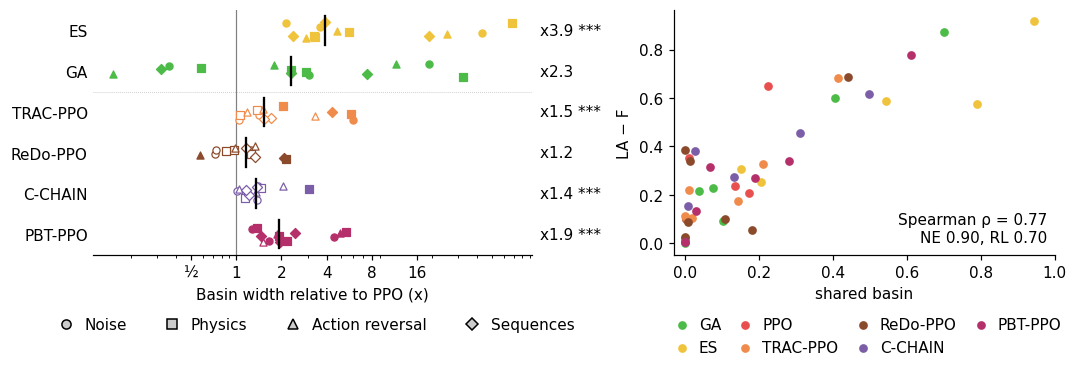

44 (setting, method) points


In [11]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={'width_ratios': [1.15, 1]})

# Left: basin width relative to PPO, one point per setting, bar = median over settings.
rng = np.random.default_rng(0)
order = ['es', 'ga', 'trac', 'redo', 'cchain', 'pbt']
for r, m in enumerate(order):
    for s, lr, p in ratios[m]:
        ax.scatter(2 ** lr, r + rng.uniform(-0.2, 0.2), s=22, marker=MARKERS[widths_data[s]['group']],
                   color=COLOURS[m] if stars(p) else 'white', edgecolors=COLOURS[m], linewidths=0.8, zorder=3)
    v = np.array([x[1] for x in ratios[m]])
    ax.plot([2 ** np.median(v)] * 2, [r - 0.35, r + 0.35], color='k', lw=1.5, zorder=4)
    ax.text(1.02, r, f'x{2 ** np.median(v):.2g} {stars(wilcoxon(v).pvalue)}',
            transform=ax.get_yaxis_transform(), va='center')
ax.axvline(1, color='0.5', lw=0.8)
ax.axhline(1.5, color='0.7', lw=0.5, ls=':')
ax.set_xscale('log'); ax.set_xticks([0.5, 1, 2, 4, 8, 16]); ax.set_xticklabels(['½', '1', '2', '4', '8', '16'])
ax.set_yticks(range(len(order))); ax.set_yticklabels([NAMES[m] for m in order]); ax.set_ylim(len(order) - 0.5, -0.5)
ax.tick_params(axis='y', length=0); ax.spines['left'].set_visible(False)
ax.set_xlabel('Basin width relative to PPO (x)')
ax.legend(handles=[plt.Line2D([], [], ls='', marker=mk, mfc='0.8', mec='k', label=g) for g, mk in MARKERS.items()],
          loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=4, frameon=False, handletextpad=0.2)

# Right: the shared basin against LA - F, frozen methods left out.
kept = [p for p in shared if not p['frozen']]
for m in NAMES:
    q = [p for p in kept if p['method'] == m]
    bx.scatter([p['shared_basin'] for p in q], [p['la_minus_f'] for p in q], s=22, color=COLOURS[m], label=NAMES[m], zorder=3)
rho = lambda pts: spearmanr([p['shared_basin'] for p in pts], [p['la_minus_f'] for p in pts]).correlation
bx.text(0.98, 0.04, f"Spearman ρ = {rho(kept):.2f}\nNE {rho([p for p in kept if p['method'] in NE]):.2f}, "
        f"RL {rho([p for p in kept if p['method'] not in NE]):.2f}", transform=bx.transAxes, ha='right', va='bottom')
bx.set_xlabel('shared basin'); bx.set_ylabel('LA − F'); bx.set_xlim(-0.03, 1)
bx.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=4, frameon=False, handletextpad=0.1, columnspacing=0.6)
plt.tight_layout()
plt.show()
print(f'{len(kept)} (setting, method) points')

**Reading the figure.** Left: every point is one setting; filled points differ from PPO across trials (Mann-Whitney, Holm over settings); the bar is the median over settings and the stars a Wilcoxon test over settings. ES has the widest basin, several times PPO's. Right: a method keeps more of each task (higher LA − F) when more of its neighbourhood solves both the current and the next task, both across and within the two families.